# 07. Bài toán phân lớp: xe có thuộc phân khúc trên 1 tỉ đồng không?

**Mục tiêu học:** áp dụng các thuật toán **phân lớp** (Logistic, Naïve Bayes, SVM, Random Forest, Gradient Boosting) trên cùng dữ liệu, và học cách đánh giá phân lớp: confusion matrix, precision/recall, ROC/PR, chọn ngưỡng.

**Liên hệ lý thuyết:** `LogisticRegression.ipynb`, `NaiveBayes.ipynb`, `SVM.ipynb` (thư mục MACHINE_LEARNING).

**Bài toán:** dự đoán nhãn `cao_cap = (giá ≥ 1000 triệu)` **chỉ từ các thuộc tính của xe, không dùng giá**. (Ứng dụng: gợi ý phân khúc cho tin chưa có giá.)

**Nội dung**
1. Tạo nhãn và kiểm tra mất cân bằng
2. So sánh các thuật toán bằng cross-validation
3. Chi tiết mô hình tốt: confusion matrix, ROC, PR
4. Chọn ngưỡng quyết định
5. Diễn giải hồi quy logistic bằng odds ratio
6. Naïve Bayes và SVM: khi nào chúng phù hợp

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target, candidates
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

df = load_data(); X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             roc_auc_score, average_precision_score, f1_score, precision_recall_curve)

## 1. Tạo nhãn và kiểm tra mất cân bằng

In [2]:
THRESH = 1000        # triệu đồng
label = (df[TARGET] >= THRESH).astype(int)
print(f"Tỉ lệ xe cao cấp (≥ {THRESH} triệu): {label.mean():.1%}  ({label.sum()} / {len(label)})")
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X, label, test_size=TEST_SIZE, stratify=label, random_state=RANDOM_STATE)
print("Giữ nguyên tỉ lệ lớp (stratify):", round(yc_tr.mean(), 3), round(yc_te.mean(), 3))
print("Baseline 'luôn đoán không cao cấp': accuracy =", round(1 - label.mean(), 3), " <- accuracy tự nó gây hiểu lầm khi lớp mất cân bằng")

Tỉ lệ xe cao cấp (≥ 1000 triệu): 32.0%  (911 / 2849)
Giữ nguyên tỉ lệ lớp (stratify): 0.32 0.319
Baseline 'luôn đoán không cao cấp': accuracy = 0.68  <- accuracy tự nó gây hiểu lầm khi lớp mất cân bằng


## 2. So sánh các thuật toán bằng cross-validation

Mỗi mô hình cần tiền xử lý hợp với nó: Logistic/SVM cần chuẩn hoá số; Naïve Bayes đa thức cần đặc trưng **không âm** (dùng MinMax); cây không cần chuẩn hoá.

In [3]:
def prep(num):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), CATEGORICAL), ("num", num, NUMERIC)])

models = {
 "Logistic": Pipeline([("p", prep(StandardScaler())), ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
 "Naive Bayes (Complement)": Pipeline([("p", prep(MinMaxScaler())), ("m", ComplementNB())]),
 "SVM (RBF)": Pipeline([("p", prep(StandardScaler())), ("m", SVC(class_weight="balanced", probability=True, random_state=0))]),
 "Random Forest": Pipeline([("p", prep("passthrough")), ("m", RandomForestClassifier(300, class_weight="balanced_subsample", random_state=0, n_jobs=-1))]),
 "HistGradientBoosting": Pipeline([("p", prep("passthrough").set_params(sparse_threshold=0)), ("m", HistGradientBoostingClassifier(random_state=0))]),   # cần ma trận dày
}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = {}
for name, pipe in models.items():
    s = cross_validate(pipe, Xc_tr, yc_tr, cv=cv, scoring={"ROC AUC": "roc_auc", "PR AUC": "average_precision", "F1": "f1", "accuracy": "accuracy"}, n_jobs=-1)
    rows[name] = {k: s[f"test_{k}"].mean() for k in ["ROC AUC", "PR AUC", "F1", "accuracy"]}
res = pd.DataFrame(rows).T.sort_values("PR AUC", ascending=False); display(res.round(3))

,ROC AUC,PR AUC,F1,accuracy
Random Forest,0.993,0.985,0.939,0.961
HistGradientBoosting,0.988,0.979,0.929,0.955
SVM (RBF),0.989,0.977,0.907,0.937
Logistic,0.979,0.957,0.881,0.919
Naive Bayes (Complement),0.937,0.871,0.795,0.856


**Chọn độ đo:** `accuracy` dễ gây hiểu lầm khi lớp thiểu số nhỏ. **ROC AUC** đo khả năng xếp hạng đúng thứ tự; **PR AUC** và **F1** tập trung vào lớp dương và nhạy với mất cân bằng hơn.

## 3. Chi tiết mô hình tốt

Mô hình: Random Forest
              precision    recall  f1-score   support

      thường      0.949     0.961     0.955       388
     cao cấp      0.915     0.890     0.903       182

    accuracy                          0.939       570
   macro avg      0.932     0.926     0.929       570
weighted avg      0.938     0.939     0.938       570



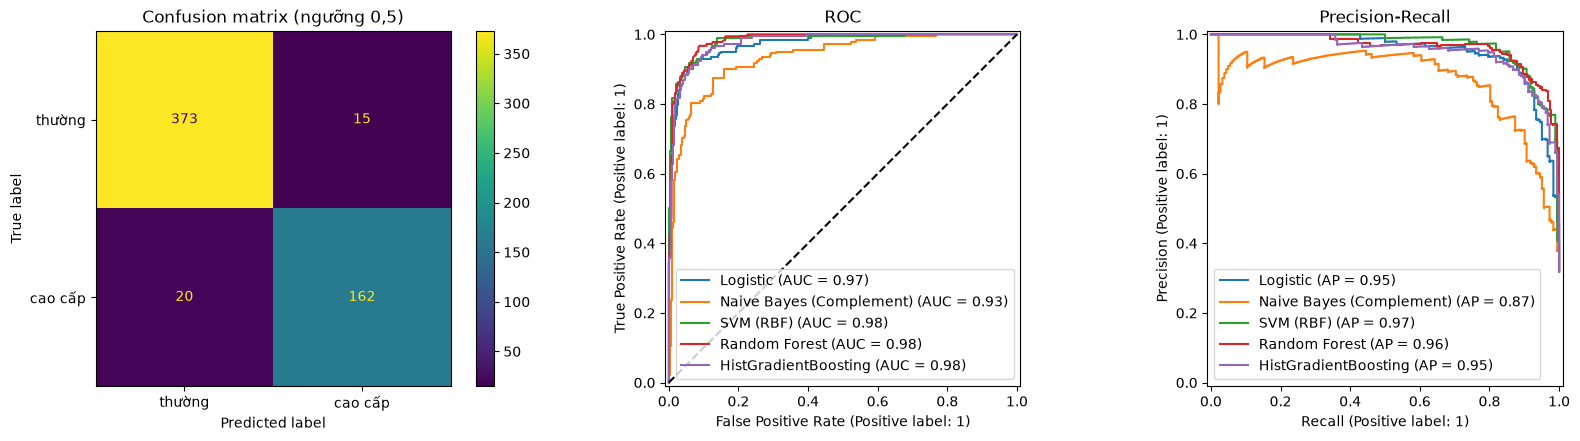

In [4]:
best_name = res.index[0]; best = models[best_name].fit(Xc_tr, yc_tr)
proba = best.predict_proba(Xc_te)[:, 1]; pred = (proba >= 0.5).astype(int)
print("Mô hình:", best_name); print(classification_report(yc_te, pred, target_names=["thường", "cao cấp"], digits=3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_te, pred, display_labels=["thường", "cao cấp"], ax=ax[0]); ax[0].set_title("Confusion matrix (ngưỡng 0,5)")
for nm, pipe in models.items():
    p = pipe.fit(Xc_tr, yc_tr).predict_proba(Xc_te)[:, 1]
    RocCurveDisplay.from_predictions(yc_te, p, name=nm, ax=ax[1]); PrecisionRecallDisplay.from_predictions(yc_te, p, name=nm, ax=ax[2])
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC"); ax[2].set_title("Precision-Recall")
plt.tight_layout(); plt.show()

## 4. Chọn ngưỡng quyết định

Ngưỡng 0,5 là mặc định, không phải tối ưu. Chọn theo **chi phí sai lầm**: nếu bỏ sót xe cao cấp tệ hơn báo nhầm, hạ ngưỡng để tăng recall; ngược lại nâng ngưỡng để tăng precision.

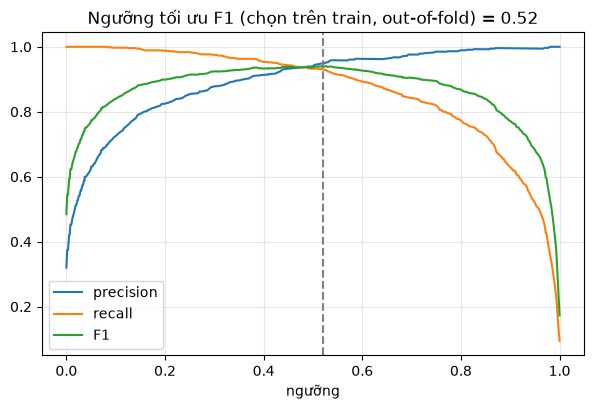

Test, ngưỡng 0.50: precision=0.915 recall=0.890 F1=0.903
Test, ngưỡng 0.52: precision=0.915 recall=0.890 F1=0.903


In [5]:
oof = cross_val_predict(models[best_name], Xc_tr, yc_tr, cv=cv, method="predict_proba")[:, 1]    # xác suất out-of-fold trên train
prec, rec, thr = precision_recall_curve(yc_tr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-9); t_best = thr[int(np.argmax(f1s))]
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall"); plt.plot(thr, f1s, label="F1"); plt.axvline(t_best, c="gray", ls="--")
plt.xlabel("ngưỡng"); plt.legend(); plt.grid(alpha=.3); plt.title(f"Ngưỡng tối ưu F1 (chọn trên train, out-of-fold) = {t_best:.2f}"); plt.show()
for t in [0.5, t_best]:
    pr = (proba >= t).astype(int)
    print(f"Test, ngưỡng {t:.2f}: precision={(pr[yc_te == 1].mean() if False else ((pr == 1) & (yc_te.values == 1)).sum() / max(pr.sum(), 1)):.3f} "
          f"recall={((pr == 1) & (yc_te.values == 1)).sum() / yc_te.sum():.3f} F1={f1_score(yc_te, pr):.3f}")

Chú ý: ngưỡng được chọn trên **dữ liệu train (out-of-fold)**, rồi mới áp dụng cho test. Chọn ngưỡng theo điểm test là một dạng nhìn trộm.

## 5. Diễn giải hồi quy logistic bằng odds ratio

In [6]:
lr = models["Logistic"].fit(Xc_tr, yc_tr)
names = lr[0].get_feature_names_out(); coef = pd.Series(lr[-1].coef_[0], index=names)
odds = np.exp(coef).rename("odds ratio")
print("Tăng khả năng là xe cao cấp (odds ratio > 1):"); display(odds.sort_values(ascending=False).head(10).round(2).to_frame())
print("Giảm khả năng (odds ratio < 1):"); display(odds.sort_values().head(10).round(3).to_frame())
print("Với biến số chuẩn hoá: age (mỗi 1 độ lệch chuẩn) odds x", round(odds["num__age"], 2), "| km:", round(odds["num__km"], 2))

Tăng khả năng là xe cao cấp (odds ratio > 1):


,odds ratio
cat__model_Land,117.20
cat__brand_Lexus,63.45
cat__brand_Bentley,30.88
cat__model_Prado,27.31
cat__brand_Porsche,19.18
cat__model_S,13.09
cat__model_SantaFe,12.86
cat__brand_BMW,12.42
cat__brand_Mercedes Benz,11.44
cat__model_Carnival,9.88


Giảm khả năng (odds ratio < 1):


,odds ratio
cat__brand_Mitsubishi,0.038
cat__model_Innova,0.046
cat__brand_Mazda,0.064
cat__brand_MG,0.075
cat__brand_Nissan,0.092
cat__model_Corolla,0.147
cat__brand_VinFast,0.154
cat__model_Territory,0.194
cat__brand_Honda,0.212
cat__brand_Suzuki,0.216


Với biến số chuẩn hoá: age (mỗi 1 độ lệch chuẩn) odds x 0.29 | km: 0.4


**Cách đọc:** `odds ratio = 3` nghĩa là khi đặc trưng đó xuất hiện (hoặc tăng 1 độ lệch chuẩn), odds của "cao cấp" nhân 3, **giữ các yếu tố khác không đổi**.

## 6. Naïve Bayes và SVM: khi nào chúng phù hợp

In [7]:
nb_f1 = f1_score(yc_te, models["Naive Bayes (Complement)"].fit(Xc_tr, yc_tr).predict(Xc_te))
svm_f1 = f1_score(yc_te, models["SVM (RBF)"].fit(Xc_tr, yc_tr).predict(Xc_te))
print(f"F1 test: Naive Bayes = {nb_f1:.3f} | SVM = {svm_f1:.3f}")

F1 test: Naive Bayes = 0.815 | SVM = 0.886


- **Naïve Bayes** giả định các đặc trưng độc lập có điều kiện: ở đây `brand`, `model`, `origin` rất phụ thuộc nhau (một dòng xe thuộc đúng một hãng), nên giả định bị vi phạm nặng. Dù vậy NB vẫn có thể cho thứ hạng khá; nhưng xác suất đầu ra thường quá tự tin. NB mạnh nhất với văn bản nhiều đặc trưng thưa.
- **SVM (RBF)** cần chuẩn hoá và tốn thời gian khi nhiều mẫu; hợp với dữ liệu vừa phải, biên phi tuyến.
- **Logistic** là baseline mạnh và dễ diễn giải; **cây/ensemble** bắt được tương tác (vd. "xe hybrid + hãng Lexus") nên thường dẫn đầu trên dữ liệu bảng.

## Bài tập
1. Đổi ngưỡng cao cấp thành 700 hoặc 2000 triệu. Mức mất cân bằng và xếp hạng mô hình thay đổi thế nào?
2. Bỏ `class_weight="balanced"` ở Logistic. Precision/recall thay đổi ra sao? Vì sao?
3. Bài toán mới: gắn nhãn tin là **"rao cao"** khi giá thật > 1,15 × giá mô hình hồi quy dự đoán (dùng dự đoán out-of-fold của notebook 03). Huấn luyện bộ phân lớp để đoán nhãn này từ các thuộc tính của xe. Có đoán được không? Vì sao câu trả lời "khó" lại hợp lý?
4. Hiệu chuẩn xác suất: vẽ `CalibrationDisplay` cho Logistic, Naïve Bayes và Random Forest. Mô hình nào tự tin quá mức?
5. Đổi bài toán thành phân lớp **nhiều lớp** (rẻ / tầm trung / cao / sang). Dùng softmax (Logistic) và so sánh với Random Forest.